# 00a · Data quality: what you can and can't trust

**Start here.** The notebooks in `analysis/` are meant to be read in order. The first three (**00a → 00b → 00c**)
look at the data itself. The next six (A–F, files `01`–`06`) build the analysis on top of it. This notebook checks
the raw data and sets out the cleaning rules that every later notebook relies on. All numbers come from the cleaned
files in `data/cleaned/` (produced by `python -m sbanalytics.pipeline`) and are loaded through `sbanalytics.data`.
The same code runs on every floor.

### Summary: what you can and can't trust

Keep these points in mind when reading notebooks 01–06. "§" refers to the numbered sections of this notebook.

| Data | Can you use it? | Where to look |
|---|---|---|
| **Energy totals** (AC, lighting and plug load, per floor) | **Yes.** Cleaning changes each floor's totals by less than 0.4%. Missing readings are left blank (NaN) and are never counted as zero. | §1, §3 |
| **Power-meter coverage** | **Yes, outside the known outages.** Outside those periods, 98.8% of the expected one-minute readings arrived (95–100% per floor). Over the full record the figure is 94.8%. | §2 |
| **Indoor temperature, humidity (RH) and light (lux), 12–15 Sep 2018 to 6 Mar 2019** | **No data.** Every indoor sensor on every floor went silent in this period (the "sensor blackout"). Different zones stopped on slightly different days. Comfort analysis can only use Jul to mid-Sep 2018 and Mar–Dec 2019. | §2 |
| **Comparing 2018 indoor temperatures with 2019** | **Avoid.** When the sensors came back on 6 Mar 2019 they read 2–3 °C colder than before (the F5 change-point). Any 2018-vs-2019 temperature comparison mixes a real change with this sensor change. | §2, `registry.CHANGE_POINTS` |
| **F6 after 2019-10-22 13:27** | **No data.** The source file was cut off at this point, so yearly F6 figures cover only 9.7 months. | §1, §2 |
| **F3, 11 Oct – 21 Nov 2018; F4, 29 Oct – 21 Nov 2018** | **No data.** Every meter on the floor was offline. Treat these weeks as missing, not as weeks of low use. | §2 |
| **Large AC meters, 23 Jan – 12 Feb 2019 (F2, F3, F5, F7)** | **No AC data.** The large AC meters all dropped out together. AC totals for these weeks are too low because data is missing, not because energy was saved. | §2 |
| **`lux` (light level) readings** | **Use only to see rises and falls.** The values are a scaled index that follows the lamps switching on and off. They are not true light levels. | `registry`, 00c (F2, F3) |
| **Zone-level AC on F3/F4/F5/F7 zone 1 and F6 zone 4** | **Check which unit carries the load.** In these zones almost all the cooling is on the unit named `AC4`, and the other units draw only trace amounts. F7 `z1_AC1` and F2 `z2_AC11` never draw any power. | §4 |
| **Floor 1 timestamps and schedule** | **Uncertain.** F1 is not an office floor, and its clock may be 7 hours out. F1 is included in energy totals but left out of anything based on working hours. | §5, §6 |
| **Comparing F5 zones 2 and 4 before and after 2019-09-27** | **Avoid.** Cooling energy was moved from one zone's meter to the other's, while the two zones' combined load stayed the same. | §7 |

**Cleaning rules.** The same rules are applied to all seven floors (code in `src/sbanalytics/clean.py`):

| # | Problem | What the cleaner does | Why |
|---|---|---|---|
| 1 | Physically impossible values | Values outside the limits set for each meter or sensor in `registry.py` are blanked (set to NaN) | Each point has its own sensible range |
| 2 | Logger glitches found by hand (F4, F5) | Values above the limits the floor owners identified are blanked | Keeps what the floor owners found in their own checks |
| 3 | Reconnect bursts: brief, huge spikes when a meter comes back online (e.g. 4,762 kW on a lighting meter) | A reading is blanked if it is more than 3 times the meter's 99.9th-percentile value, lasts 3 minutes or less, and the surrounding readings (rolling median) are below a third of that limit | A burst is brief; a real increase in load lasts |
| 4 | Short gaps | Gaps of 5 minutes or less inside a run of data are filled in by interpolation | Longer gaps (outages, the blackout) are never filled |
| 5 | Stuck sensors (the same value repeated for a long time) | Flagged in the health table but not deleted | Deleting a frozen but plausible meter would distort totals more than keeping it |
| 6 | Hour and day coverage | An hour is usable for modelling if at least 48 of its 60 minutes are present; a day is usable if at least 20 of its hours are | Totals add up whatever arrived; these flags decide what the models may use |

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="obj.round has no effect")
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # viz falls back from Segoe UI quietly

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# `pip install -e .` from the repo root makes `sbanalytics` importable; this fallback works without it.
try:
    import sbanalytics
except ImportError:
    import sys
    from pathlib import Path
    sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sbanalytics").is_dir()) / "src"))

from sbanalytics import data as D, registry as R, viz
viz.setup()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 120)
from sbanalytics import io, clean as CL, anomaly as AN, baseline as B, features as FT, config as C

## 1 · What the pipeline built

Energy per floor before and after cleaning. Cleaning should change totals by well under 1%. A bigger change would
mean a rule is removing data it should not.

In [2]:
s = pd.read_csv(C.DATA_CLEANED / "build_summary.csv").set_index("floor")
tbl = pd.DataFrame({
    "first reading": s["first"], "last reading": s["last"],
    "minutes with data": s.rows_with_data,
    **{f"{ch.upper()} MWh (raw)": (s[f"{ch}_kwh_raw"] / 1000).round(1) for ch in ("ac", "light", "plug")},
    **{f"{ch.upper()} change %": ((s[f"{ch}_kwh_clean"] / s[f"{ch}_kwh_raw"] - 1) * 100).round(2) for ch in ("ac", "light", "plug")},
    "minutes changed": s.minutes_changed,
})
tbl

,first reading,last reading,minutes with data,AC MWh (raw),LIGHT MWh (raw),PLUG MWh (raw),AC change %,LIGHT change %,PLUG change %,minutes changed
floor,,,,,,,,,,
1,2018-07-01 00:00:00,2019-12-31 23:59:00,789493,435.6,722.8,239.4,0.01,-0.00,0.06,2822
2,2018-07-01 00:00:00,2019-12-31 23:59:00,789692,284.9,58.6,21.5,0.05,0.02,0.00,43226
3,2018-07-01 00:00:00,2019-12-31 23:59:00,731050,162.4,74.7,17.6,0.06,0.01,-0.13,55768
4,2018-07-01 00:00:00,2019-12-31 23:59:00,756772,180.0,56.8,27.9,0.06,0.28,0.05,51093
5,2018-07-01 00:00:00,2019-12-31 23:59:00,783828,177.9,74.1,22.4,0.24,0.35,0.04,74542
6,2018-07-01 00:00:00,2019-10-22 13:27:00,688318,146.8,82.6,19.1,0.07,0.10,0.04,48983
7,2018-07-01 00:00:00,2019-12-31 23:59:00,789618,293.3,74.8,9.2,0.04,0.17,0.13,69167


Every floor starts on 2018-07-01 00:00. **F6 stops at 2019-10-22 13:27.** The 2019 file for F6 was cut off during
download, and its last row is damaged (`Date = "2"`), so `io.load_raw` drops that row rather than guessing its
timestamp. On every floor, cleaning changes each end use (AC, lighting, plug) by no more than 0.35%.

## 2 · Coverage: which data exist, and when

Each row is one measurement point (a floor, zone and channel, such as `z2_AC1` or temperature; meters that never work
are left out). Each column is one day. The colour shows the share of that day's one-minute readings that arrived,
measured **before** cleaning (from `point_day_health.parquet`). **White means nothing arrived.** Red outlines mark the
five major outages that every analysis has to allow for.

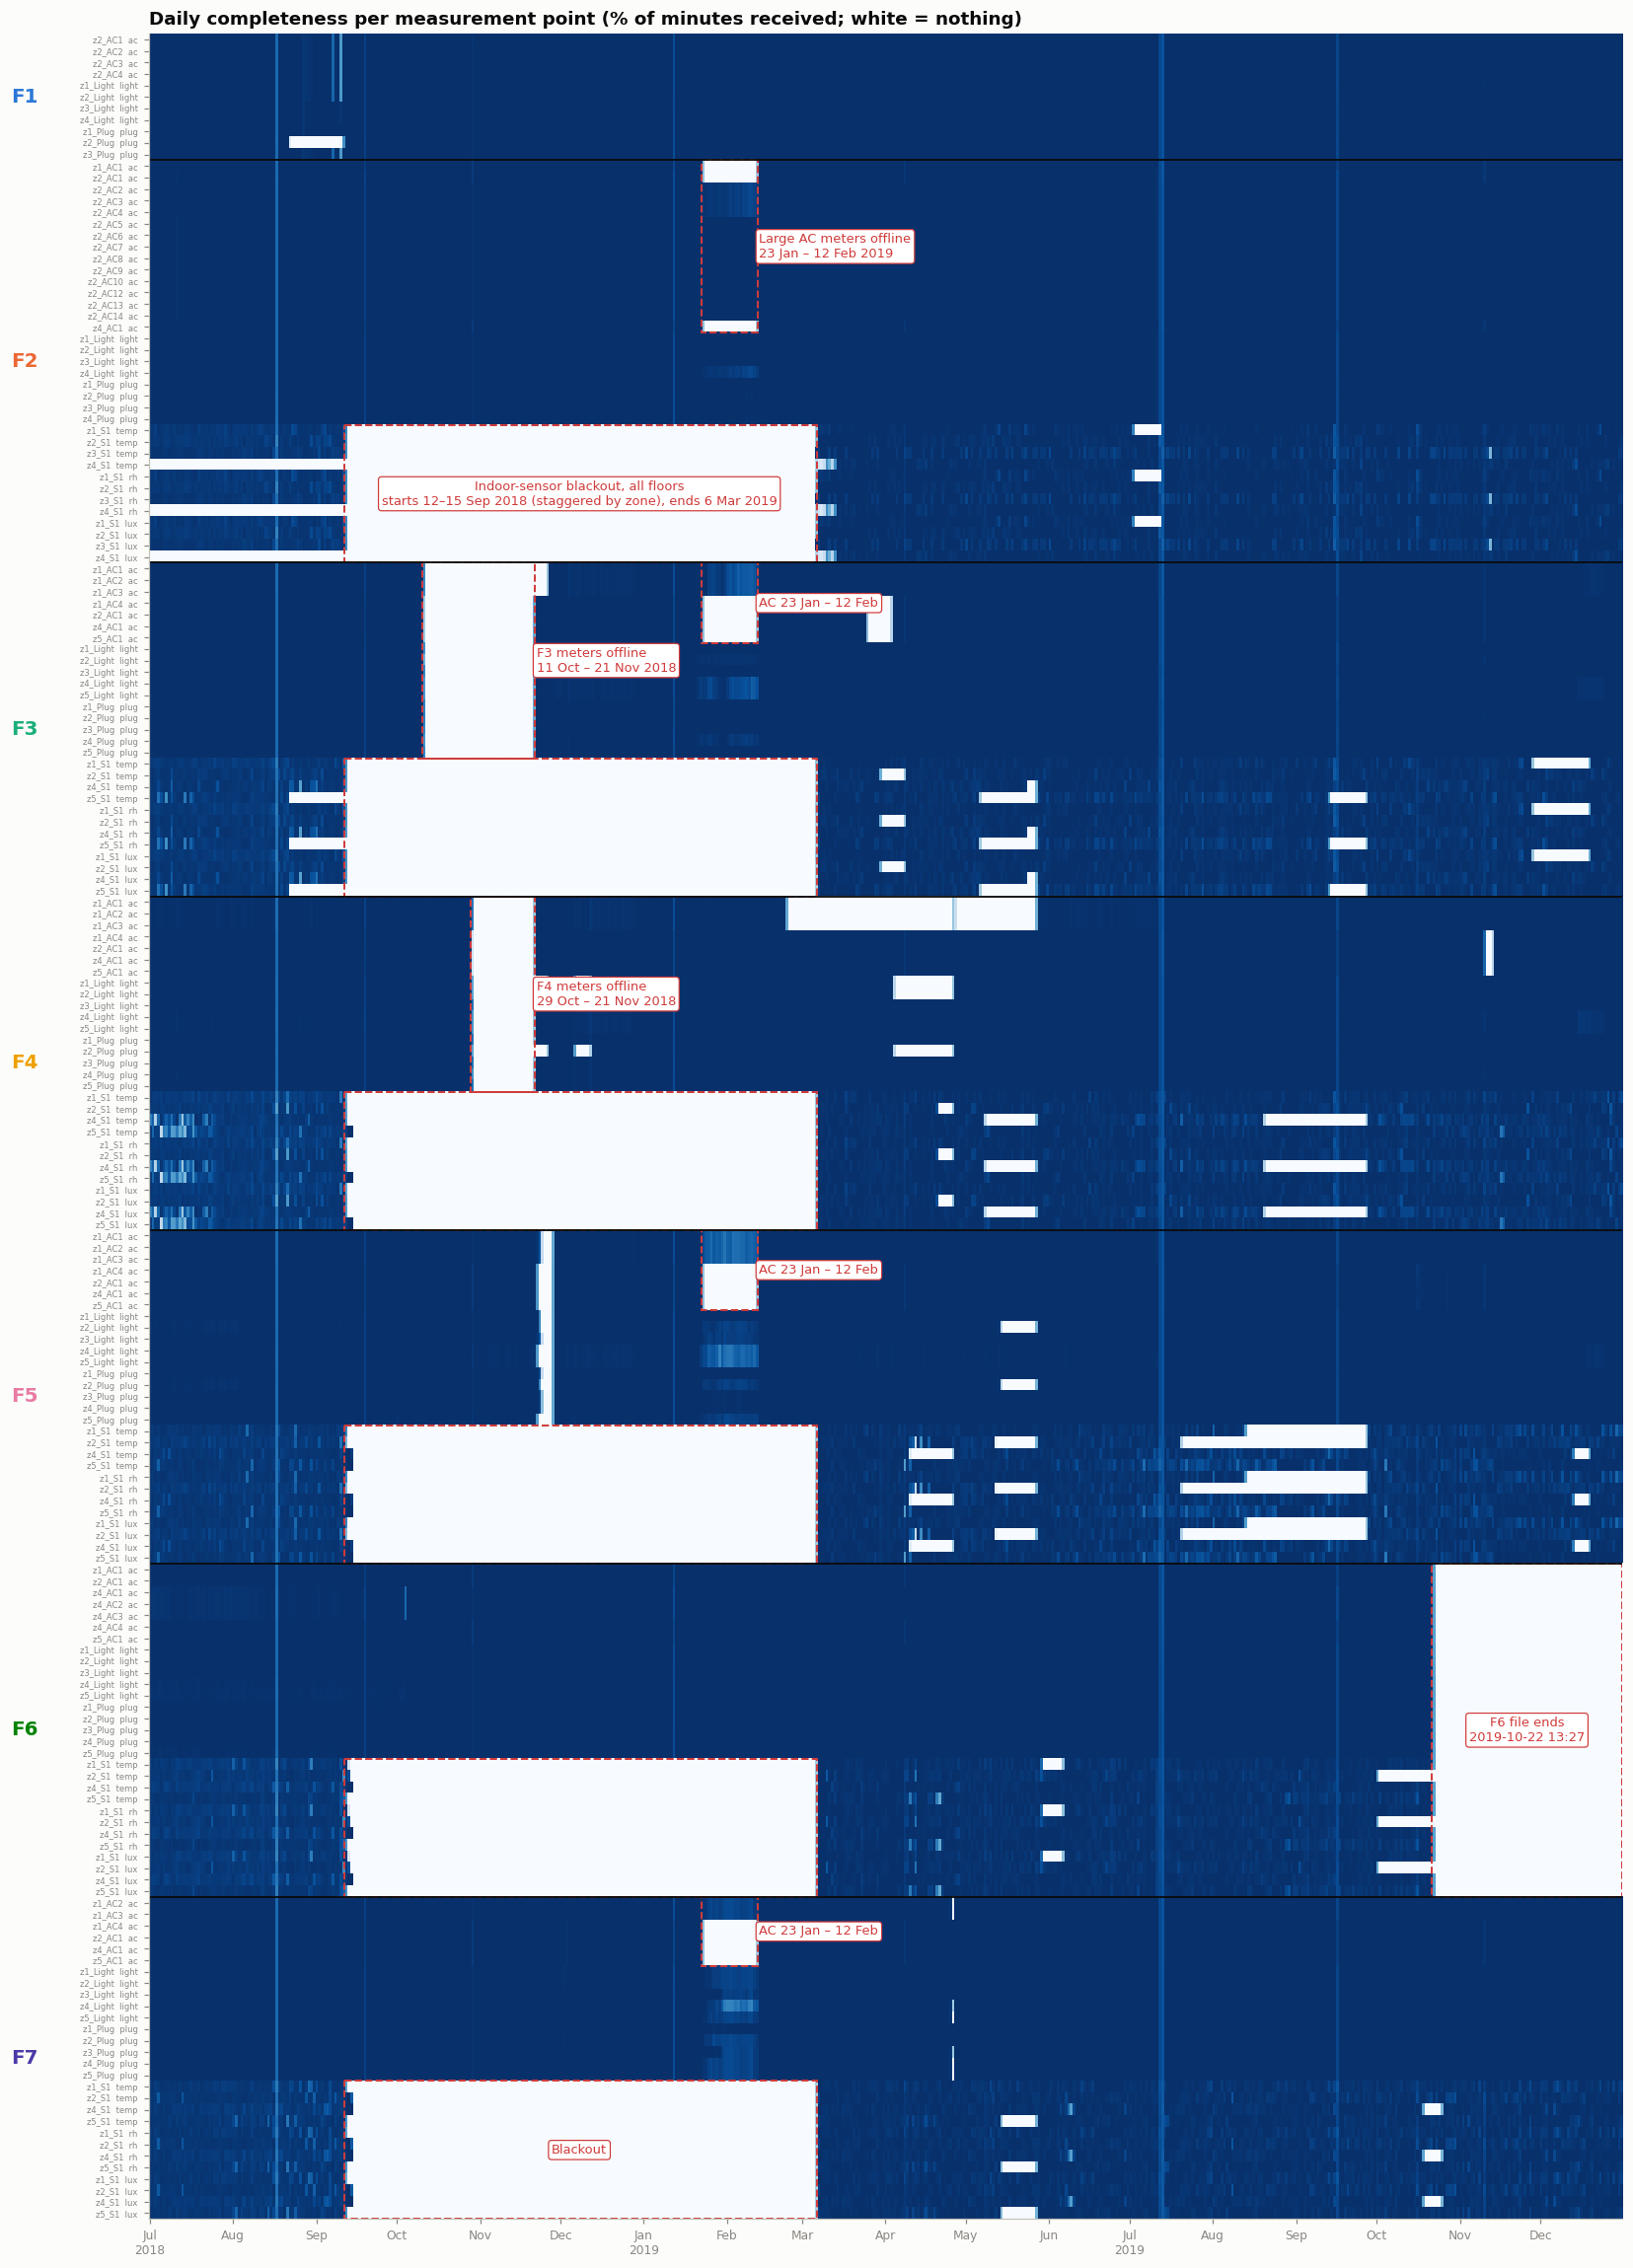

In [3]:
import re
import matplotlib.patches as mpatches
from matplotlib.transforms import blended_transform_factory

H = D.load_health(None)
H = H[H.role != R.ROLE_DEAD]
CH_ORDER = ["ac", "light", "plug", "temp", "rh", "lux"]
SENSORS, POWER = ["temp", "rh", "lux"], ["ac", "light", "plug"]

pts = H[["floor", "zone", "channel", "column"]].drop_duplicates()
pts = pts.assign(ch=pts.channel.map(CH_ORDER.index),
                 nat=pts.column.map(lambda c: re.sub(r"\d+", lambda m: m.group().zfill(3), c)))   # z2_AC2 before z2_AC10
pts = pts.sort_values(["floor", "ch", "nat"]).reset_index(drop=True)
grid = H.pivot_table(index=["floor", "column"], columns="day", values="completeness")
grid = grid.reindex(pd.MultiIndex.from_frame(pts[["floor", "column"]]))
days = grid.columns

#: The five outages named in data/cleaned/README.md: (label, floors, channels, first day, last day).
NAMED = [
    ("Indoor-sensor blackout", [2, 3, 4, 5, 6, 7], SENSORS, "2018-09-12", "2019-03-06"),
    ("F3 meters offline", [3], POWER, "2018-10-11", "2018-11-21"),
    ("F4 meters offline", [4], POWER, "2018-10-29", "2018-11-21"),
    ("Large AC meters offline", [2, 3, 5, 7], ["ac"], "2019-01-23", "2019-02-12"),
    ("F6 file ends 2019-10-22 13:27", [6], POWER + SENSORS, "2019-10-22", "2019-12-31"),
]

def xi(d):
    return days.get_indexer([pd.Timestamp(d)])[0]

def rows_of(floor, channels):
    idx = pts.index[(pts.floor == floor) & pts.channel.isin(channels)]
    return (idx.min(), idx.max()) if len(idx) else None

fig, ax = plt.subplots(figsize=(15, 21))
ax.imshow(grid.to_numpy(), aspect="auto", cmap=viz.SEQUENTIAL, vmin=0, vmax=100, interpolation="nearest")
ax.grid(False)
ax.set_yticks(range(len(pts)), [f"{c.split('(')[0]}  {ch}" for c, ch in zip(pts.column, pts.channel)], fontsize=5.5)
months = [i for i, d in enumerate(days) if d.day == 1]
ax.set_xticks(months, [days[i].strftime("%b\n%Y") if days[i].month in (1, 7) else days[i].strftime("%b") for i in months], fontsize=8)

trans = blended_transform_factory(ax.transAxes, ax.transData)
for f, g in pts.groupby("floor"):
    lo, hi = g.index.min(), g.index.max()
    if lo:
        ax.axhline(lo - 0.5, color=viz.INK, lw=1.2)
    ax.text(-0.075, (lo + hi) / 2, f"F{f}", transform=trans, fontsize=13, fontweight="bold",
            color=viz.FLOOR_COLORS[f], ha="right", va="center")

RED = viz.STATUS["critical"]
box = dict(boxstyle="round,pad=0.25", fc="white", ec=RED, lw=0.8)
for label, floors, chans, d0, d1 in NAMED:
    for f in floors:
        r = rows_of(f, chans)
        if r is None:
            continue
        ax.add_patch(mpatches.Rectangle((xi(d0) - 0.5, r[0] - 0.5), xi(d1) - xi(d0) + 1, r[1] - r[0] + 1,
                                        fill=False, ec=RED, lw=1.3, ls="--"))

def note(text, floor, chans, x_day, dy=0.0, ha="center"):
    r = rows_of(floor, chans)
    ax.text(xi(x_day), (r[0] + r[1]) / 2 + dy, text, fontsize=8.5, color=RED, ha=ha, va="center", bbox=box)

note("Indoor-sensor blackout, all floors\nstarts 12–15 Sep 2018 (staggered by zone), ends 6 Mar 2019", 2, SENSORS, "2018-12-08")
note("Blackout", 7, SENSORS, "2018-12-08")
note("F3 meters offline\n11 Oct – 21 Nov 2018", 3, POWER, "2018-11-22", ha="left")
note("F4 meters offline\n29 Oct – 21 Nov 2018", 4, POWER, "2018-11-22", ha="left")
for f in (2, 3, 5, 7):
    note("Large AC meters offline\n23 Jan – 12 Feb 2019" if f == 2 else "AC 23 Jan – 12 Feb", f, ["ac"], "2019-02-13", ha="left")
note("F6 file ends\n2019-10-22 13:27", 6, POWER + SENSORS, "2019-11-26")
ax.set_title("Daily completeness per measurement point (% of minutes received; white = nothing)")
fig.tight_layout()

**How to read the chart**

* **The indoor-sensor blackout** is the large white block across the temperature, humidity and lux rows of every
  floor (F1 has no sensors). It did not start on a single day: each zone's last reading falls between 12 Sep and
  midnight on 14/15 Sep 2018 (see the table below). F3 zone 5 had already gone silent on 21 Aug, and F2 zone 4 has no
  sensor data at all in 2018. All sensors came back within minutes of each other, at about 14:20 on 6 Mar 2019.
* **F3 (11 Oct – 21 Nov 2018) and F4 (29 Oct – 21 Nov 2018)** lose every power meter at the same moment. That points
  to a network or gateway failure rather than faults in individual meters.
* **23 Jan – 12 Feb 2019:** only the *large* AC meters on F2, F3, F5 and F7 go silent. The small AC units and the
  lighting and plug meters keep reporting, so the large AC meters must use a separate communication link (see the F3
  profile in 00c). F4 and F6 are not affected.
* **F6** is blank after 22 Oct 2019 because its file ends there.
* Smaller gaps that the data README does not mention are listed in the outage register below. Examples: F1 `z2_Plug`
  (23 Aug – 10 Sep 2018), F4 `z1_AC1–3` (Feb – May 2019), F5's zone 1 and zone 2 sensors (Aug – Sep 2019) and F6
  zone 2's sensor (from 2 Oct 2019).

In [4]:
temp = H[H.channel == "temp"]
alive = temp[temp.received > 0]
stagger = pd.DataFrame({
    "last day with data before": alive[alive.day < "2018-10-01"].groupby(["floor", "zone"]).day.max(),
    "first day back": alive[alive.day > "2018-12-01"].groupby(["floor", "zone"]).day.min(),
})
stagger["days dark"] = (stagger["first day back"] - stagger["last day with data before"]).dt.days - 1
has_sensor = temp.groupby(["floor", "zone"]).size().index          # zones that have a sensor at all
tbl = (stagger.reindex(has_sensor)["last day with data before"].dt.strftime("%d %b %Y").fillna("none in 2018")
       .unstack("floor").fillna("no sensor"))
tbl

floor,2,3,4,5,6,7
zone,,,,,,
z1,12 Sep 2018,12 Sep 2018,12 Sep 2018,12 Sep 2018,13 Sep 2018,12 Sep 2018
z2,12 Sep 2018,12 Sep 2018,12 Sep 2018,12 Sep 2018,13 Sep 2018,14 Sep 2018
z3,12 Sep 2018,no sensor,no sensor,no sensor,no sensor,no sensor
z4,none in 2018,12 Sep 2018,12 Sep 2018,14 Sep 2018,14 Sep 2018,14 Sep 2018
z5,no sensor,21 Aug 2018,14 Sep 2018,14 Sep 2018,12 Sep 2018,12 Sep 2018


The table above shows, for each floor and zone, the last day the temperature sensor reported before the blackout.
Every zone comes back on 6 Mar 2019. The exact times for F5 are recorded in `registry.CHANGE_POINTS`: zone 2 stops
at 11:09 and zone 1 at 16:33 on 12 Sep, while zones 4 and 5 stop at exactly 00:00 on 15 Sep. A cut-off at exactly
midnight looks more like a problem with the data export than a hardware failure.

### How complete are the power meters?

The share of expected one-minute readings that actually arrived, for every meter that carries energy (meters that
never work are left out). It is shown over the full record and with the named outages removed. The data README says
the power meters are "~99% complete", and that holds **outside the named outages** (98.8%). Over the full record,
the outages bring F3, F4 and F6 down to 87–91%.

In [5]:
pw = H[H.channel.isin(POWER)].copy()
named_mask = pd.Series(False, index=pw.index)
for _, floors, chans, d0, d1 in NAMED:
    named_mask |= pw.floor.isin(floors) & pw.channel.isin(chans) & pw.day.between(d0, d1)

def pct(d):
    return d.received.sum() / d.expected.sum() * 100

power_cov = pd.DataFrame({
    "full record %": pw.groupby("floor").apply(pct, include_groups=False),
    "outside named outages %": pw[~named_mask].groupby("floor").apply(pct, include_groups=False),
})
power_cov.loc["all floors"] = [pct(pw), pct(pw[~named_mask])]
sens = H[H.channel.isin(SENSORS)]
print(f"Sensors (temp/RH/lux): {pct(sens):.1f}% of minutes over the full record, "
      f"{pct(sens[~sens.in_blackout]):.1f}% outside the blackout.")
power_cov.round(1)

Sensors (temp/RH/lux): 61.2% of minutes over the full record, 89.7% outside the blackout.


,full record %,outside named outages %
floor,,
1,99.4,99.4
2,99.3,99.8
3,90.8,99.1
4,91.4,95.4
5,97.5,98.4
6,87.0,99.8
7,98.7,99.6
all floors,94.8,98.8


### Outage register

Every stretch of 3 or more days in a row in which a point received less than 5% of its readings, grouped by floor,
channel and dates. The `named` column says which of the five major outages the stretch belongs to; a dash means it is
a smaller gap specific to that floor. No analysis may treat these periods as zero use.

In [6]:
runs = []
for (f, col), g in H.sort_values("day").groupby(["floor", "column"]):
    off = g.completeness < 5
    run_id = (off != off.shift()).cumsum()
    for _, e in g[off].groupby(run_id[off]):
        if len(e) >= 3:
            runs.append({"floor": f, "channel": e.channel.iloc[0], "zone": e.zone.iloc[0], "column": col,
                         "from": e.day.min(), "to": e.day.max(), "days": len(e)})
runs = pd.DataFrame(runs)
runs["channel"] = np.where(runs.channel.isin(SENSORS), "sensors", runs.channel)

def which_named(r):
    for label, floors, chans, d0, d1 in NAMED:
        ch_ok = (r.channel == "sensors" and set(chans) & set(SENSORS)) or r.channel in chans
        if r.floor in floors and ch_ok and r["from"] <= pd.Timestamp(d1) and r["to"] >= pd.Timestamp(d0):
            return label
    return "—"

outages = (runs.groupby(["floor", "channel", "from", "to", "days"])
           .agg(points=("column", "nunique"), zones=("zone", lambda s: ", ".join(sorted(set(s)))))
           .reset_index().sort_values(["floor", "from", "channel"]))
outages["named"] = outages.apply(which_named, axis=1)
outages["from"], outages["to"] = outages["from"].dt.date, outages["to"].dt.date
outages.reset_index(drop=True)

,floor,channel,from,to,days,points,zones,named
0,1,plug,2018-08-23,2018-09-10,19,1,z2,—
1,2,sensors,2018-07-01,2019-03-05,248,3,z4,Indoor-sensor blackout
2,2,sensors,2018-09-13,2019-03-05,174,9,"z1, z2, z3",Indoor-sensor blackout
3,2,ac,2019-01-24,2019-02-11,19,3,"z1, z2, z4",Large AC meters offline
4,2,sensors,2019-07-03,2019-07-12,10,3,z1,—
5,3,sensors,2018-08-22,2019-03-05,196,3,z5,Indoor-sensor blackout
6,3,sensors,2018-09-13,2019-03-05,174,9,"z1, z2, z4",Indoor-sensor blackout
7,3,ac,2018-10-12,2018-11-20,40,4,"z1, z2, z4, z5",F3 meters offline
8,3,ac,2018-10-12,2018-11-25,45,3,z1,F3 meters offline
9,3,light,2018-10-12,2018-11-20,40,5,"z1, z2, z3, z4, z5",F3 meters offline


## 3 · What cleaning changed

The number of minutes each rule changed on each floor. The full detail, including the first and last timestamp of
every change, is in `data/cleaned/cleaning_log.csv`. Interpolation only fills gaps of 5 minutes or less, and each of
the other rules touches a few dozen minutes per floor.

In [7]:
log = pd.read_csv(C.DATA_CLEANED / "cleaning_log.csv")
display(log.pivot_table(index="floor", columns="rule", values="minutes", aggfunc="sum", fill_value=0))
log[log.rule != "interpolated"].sort_values("minutes", ascending=False).head(10)[["floor", "column", "rule", "minutes", "detail"]]

rule,glitch_cap,interpolated,range,spike
floor,,,,
1,0,2723,96,3
2,0,43186,0,40
3,0,55427,14,327
4,9,51060,1,23
5,26,74396,39,81
6,0,48918,0,65
7,0,69157,0,10


,floor,column,rule,minutes,detail
2,1,z2_AC1(kW),range,84,"outside [0, 80] kW"
88,3,z3_Plug(kW),spike,59,"> 2.55 kW, <= 3 min"
92,3,z4_Light(kW),spike,45,"> 10.47 kW, <= 3 min"
103,3,z5_Plug(kW),spike,40,"> 3.84 kW, <= 3 min"
101,3,z5_Light(kW),spike,37,"> 9.21 kW, <= 3 min"
94,3,z4_Plug(kW),spike,36,"> 5.28 kW, <= 3 min"
168,5,z2_Light(kW),spike,35,"> 14.13 kW, <= 3 min"
86,3,z3_Light(kW),spike,33,"> 4.98 kW, <= 3 min"
70,3,z1_Light(kW),spike,32,"> 18.15 kW, <= 3 min"
72,3,z1_Plug(kW),spike,26,"> 5.94 kW, <= 3 min"


**Example: the largest spike in the dataset.** F1 `z3_Light` reads 4,762 kW for a single minute, about 50 times its
normal maximum. Below, the cleaner is re-run on the raw file (so the cached minute data is not needed). It removes the
spike and leaves the readings around it unchanged.

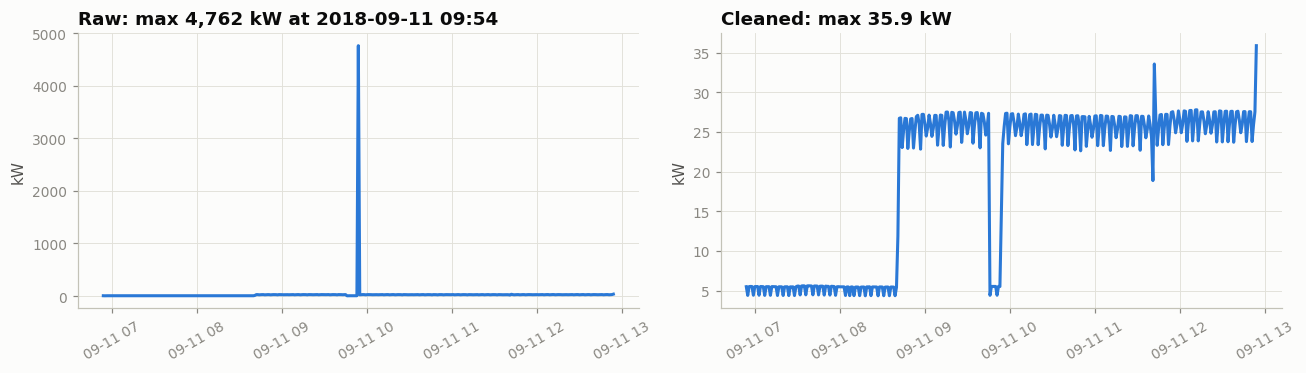

In [8]:
raw1 = io.load_raw(1)
clean1, _ = CL.clean_floor(raw1, 1)
col = "z3_Light(kW)"
t = raw1[col].idxmax()
lo, hi = t - pd.Timedelta(hours=3), t + pd.Timedelta(hours=3)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
axes[0].plot(raw1.loc[lo:hi, col], color=viz.FLOOR_COLORS[1])
axes[0].set_title(f"Raw: max {raw1[col].max():,.0f} kW at {t:%Y-%m-%d %H:%M}")
axes[1].plot(clean1.loc[lo:hi, col], color=viz.FLOOR_COLORS[1])
axes[1].set_title(f"Cleaned: max {clean1.loc[lo:hi, col].max():,.1f} kW")
for a in axes:
    a.set_ylabel("kW"); a.tick_params(axis="x", rotation=30)
fig.tight_layout()
del raw1, clean1

## 4 · Meter roles: dead, residual and always-on units

The status of each AC meter over the whole record:

* *Dead*: the meter never records any power.
* *Residual*: the unit draws only a trace amount, while another unit in the same zone does the real cooling.
* *Always-on*: the unit is running in more than 80% of night hours (01:00–04:59).

These statuses are recorded as role overrides in `registry.py`, and the always-on units are candidates for the
recommendations in `06`.

In [9]:
hp = D.load_hourly_points()
units = AN.unit_status(hp)
units[units.status != "scheduled"].round(3)

,floor,zone,column,role,kwh,hours,on_share,night_on_share,floor_share,status
0,1,z2,z2_AC1(kW),primary,368478.88,13152,7.76e-01,9.87e-01,0.85,always-on
2,1,z2,z2_AC3(kW),residual,109.33,13152,0.00e+00,0.00e+00,0.00,rarely runs
3,1,z2,z2_AC4(kW),residual,96.61,13152,0.00e+00,0.00e+00,0.00,rarely runs
5,2,z2,z2_AC1(kW),primary,77045.85,12677,9.43e-01,9.98e-01,0.27,always-on
15,2,z2,z2_AC6(kW),primary,7710.68,13165,7.85e-01,9.98e-01,0.03,always-on
10,2,z2,z2_AC14(kW),residual,93.71,13165,9.00e-03,0.00e+00,0.00,rarely runs
8,2,z2,z2_AC12(kW),residual,92.33,13165,9.00e-03,0.00e+00,0.00,rarely runs
7,2,z2,z2_AC11(kW),dead,0.00,13165,0.00e+00,0.00e+00,0.00,dead
20,3,z1,z1_AC1(kW),residual,26.74,12064,2.00e-03,0.00e+00,0.00,rarely runs
29,4,z1,z1_AC3(kW),residual,12.40,10403,2.00e-03,0.00e+00,0.00,rarely runs


**Watch out for zone 1.** On F3, F4, F5 and F7, zone 1 has four AC meters and the real load is on `AC4`. On F6, the
zone with four meters is zone 4. Code that adds up only the `*_AC1` meters across zones would quietly miss between a
fifth and a third of the floor's cooling. (F1 zone 2 also has four units, but there `AC1` carries the load and `AC2`
helps out at certain times of year.)

In [10]:
four = units[units.groupby(["floor", "zone"]).column.transform("size") == 4].copy()
four["share of zone AC"] = four.kwh / four.groupby(["floor", "zone"]).kwh.transform("sum")
four["unit"] = four.column.str.extract(r"_(AC\d)", expand=False)
(four.pivot_table(index=["floor", "zone"], columns="unit", values="share of zone AC") * 100).round(2).astype(str) + "%"

,unit,AC1,AC2,AC3,AC4
floor,zone,,,,
1,z2,84.58%,15.38%,0.03%,0.02%
3,z1,0.05%,0.15%,0.16%,99.65%
4,z1,0.01%,0.2%,0.02%,99.77%
5,z1,0.01%,0.2%,0.14%,99.66%
6,z4,0.08%,0.48%,0.08%,99.36%
7,z1,0.0%,0.74%,0.76%,98.5%


## 5 · Clocks: are the timestamps in local time?

**Weather.** The ERA5 weather data (a global weather dataset) is recorded in UTC. After converting to Bangkok time,
average solar radiation should peak in the hour starting at 11:00 or 12:00, since the sun is highest at about 12:15.

In [11]:
w = D.load_weather()
solar = w.groupby(w.ts.dt.hour).out_solar.mean()
print(f"Solar radiation peaks in the hour starting {solar.idxmax()}:00 local time")

Solar radiation peaks in the hour starting 11:00 local time


**Building meters.** On an office floor, energy use rises in the morning, before the afternoon peak in outdoor
temperature. So load lines up best with outdoor temperature at a small negative lag (the load leads the temperature).
A floor whose clock was shifted would stand out with a very different best lag.

,best lag (h),corr at best lag,corr at lag 0
1,7,0.55,-0.18
2,-2,0.54,0.45
3,-2,0.47,0.36
4,-2,0.49,0.36
5,-2,0.49,0.38
6,-2,0.52,0.40
7,-2,0.50,0.41


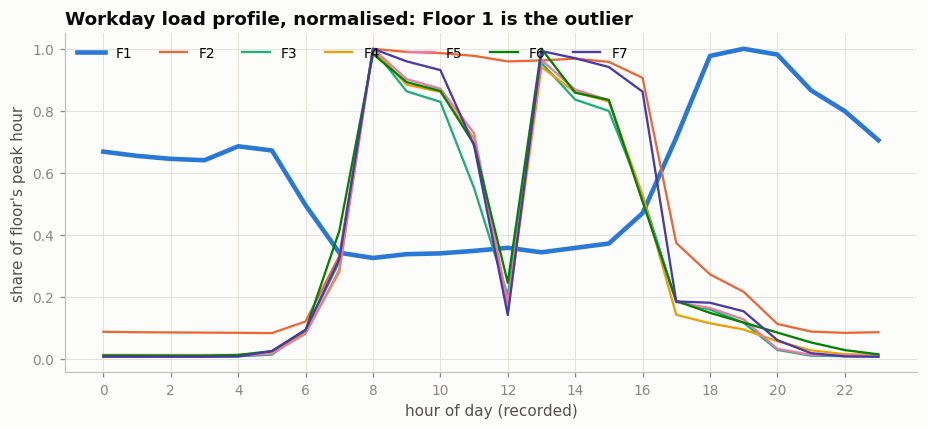

In [12]:
fh = B.floor_hourly(D.load_hourly(None))
lags = {}
for f, g in fh.groupby("floor"):
    g = g.set_index("ts").asfreq("h")
    lags[f] = {k: g.total_kwh.corr(g.out_temp.shift(k)) for k in range(-12, 13)}
lag_tbl = pd.DataFrame(lags).T
display(pd.DataFrame({"best lag (h)": lag_tbl.idxmax(axis=1), "corr at best lag": lag_tbl.max(axis=1), "corr at lag 0": lag_tbl[0]}))

prof = fh[fh.day_type == "workday"].groupby(["floor", "hour"]).total_kwh.mean().unstack("floor")
fig, ax = plt.subplots(figsize=(10, 4))
for f in prof.columns:
    ax.plot(prof.index, prof[f] / prof[f].max(), color=viz.FLOOR_COLORS[f], label=f"F{f}", lw=3 if f == 1 else 1.5)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of day (recorded)"); ax.set_ylabel("share of floor's peak hour")
ax.set_title("Workday load profile, normalised: Floor 1 is the outlier")
ax.legend(ncol=7, loc="upper left");

In [13]:
dow = fh[fh.floor == 1].groupby([fh.ts.dt.dayofweek.rename("weekday"), "hour"]).total_kwh.mean().unstack()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow.round(0)

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Mon,112.0,111.0,109.0,108.0,116.0,113.0,81.0,63.0,62.0,63.0,...,67.0,71.0,95.0,132.0,173.0,175.0,171.0,149.0,139.0,125.0
Tue,123.0,120.0,119.0,118.0,125.0,122.0,93.0,66.0,61.0,68.0,...,70.0,71.0,90.0,126.0,172.0,178.0,175.0,150.0,139.0,123.0
Wed,118.0,114.0,112.0,112.0,121.0,119.0,89.0,59.0,57.0,58.0,...,65.0,65.0,75.0,120.0,169.0,175.0,171.0,155.0,146.0,127.0
Thu,123.0,119.0,118.0,118.0,126.0,125.0,93.0,63.0,58.0,61.0,...,65.0,69.0,81.0,126.0,173.0,177.0,175.0,161.0,150.0,131.0
Fri,126.0,125.0,123.0,122.0,129.0,127.0,92.0,63.0,62.0,61.0,...,63.0,66.0,88.0,134.0,185.0,189.0,186.0,160.0,144.0,128.0
Sat,123.0,121.0,118.0,119.0,127.0,122.0,91.0,81.0,78.0,80.0,...,82.0,83.0,95.0,107.0,147.0,152.0,150.0,130.0,127.0,116.0
Sun,115.0,114.0,113.0,112.0,120.0,118.0,86.0,78.0,82.0,85.0,...,84.0,82.0,92.0,102.0,146.0,147.0,146.0,122.0,121.0,113.0


**What the evidence says about Floor 1**

* F2–F7 all line up best with outdoor temperature at the same small negative lag. They also share the same daily
  pattern: AC on at 08:00, off over lunch (except F2), and off again at 16:30. Their clocks agree with each other and
  with local time.
* F1 peaks in the evening (17:00–23:00) and is quiet during the working day. Its best lag differs from the other
  floors' by about 9 hours. A clock that is 7 hours out (the explanation suggested in the original F1 analysis) would
  account for this lag. It would also explain why F1's load is lower from 00:00 to 06:00 on Mondays, since those
  hours would really be Sunday evening.
* However, shifting the clock still does not make F1 look like an office. Its daytime load is higher at *weekends*
  than on weekdays, and its AC never switches off. F1 is a different kind of space, and lighting is its largest use
  of energy.

**Decision.** No timestamp shift is applied. The evidence is not conclusive, and a wrong shift would distort every F1
result. F1 is kept in all energy totals but **left out of measures based on working hours** (after-hours share,
baseload ratio, comfort during occupied hours) and out of the anomaly rules that rely on a schedule. Facilities
management should confirm what F1 is used for and check its logger clock. This is included in the recommendations
(`06`).

## 6 · Measured AC schedules

The schedules are read from the meter data rather than assumed. `features.measure_ac_hours` returns the hours in
which a floor's AC is on for at least half of all workdays. These are compared below with the schedule declared in
`registry.AC_ON_HOURS_BY_FLOOR`.

In [14]:
h_all = D.load_hourly(None)
sched = pd.DataFrame({
    "measured": {f: FT.measure_ac_hours(h_all, f) for f in C.FLOORS},
    "registry": {f: R.ac_on_hours(f) for f in C.FLOORS},
})
sched["agree"] = sched.measured.astype(str) == sched.registry.astype(str)
sched

,measured,registry,agree
1,[],"[8, 9, 10, 11, 12, 13, 14, 15, 16]",False
2,"[8, 9, 10, 11, 12, 13, 14, 15, 16]","[8, 9, 10, 11, 12, 13, 14, 15, 16]",True
3,"[8, 9, 10, 11, 13, 14, 15, 16]","[8, 9, 10, 11, 13, 14, 15, 16]",True
4,"[8, 9, 10, 11, 13, 14, 15, 16]","[8, 9, 10, 11, 13, 14, 15, 16]",True
5,"[8, 9, 10, 11, 13, 14, 15, 16]","[7, 8, 9, 10, 11, 13, 14, 15, 16]",False
6,"[8, 9, 10, 11, 13, 14, 15, 16]","[8, 9, 10, 11, 13, 14, 15, 16]",True
7,"[8, 9, 10, 11, 13, 14, 15, 16]","[8, 9, 10, 11, 13, 14, 15, 16]",True


F3–F7 run AC from 08:00 to 11:59 and from 13:00 to 16:59 on workdays. F2 does not switch off over lunch. F5 keeps the
schedule that was checked by hand for the dashboard, which also counts the partial hour from 07:00. F1 has no
schedule because its AC runs around the clock, so it is given a standard 08:00–17:00 window.

## 7 · Metering re-assignments between zones

**The known case: F5 on 2019-09-27.** Cooling energy moved from the zone 4 meter to the zone 2 meter, while the total
of the two barely changed. This means the meter wiring (the current transformer, or CT) was reassigned; the actual
cooling demand did not change. The switch happens on the same afternoon that the zone 1 and zone 2 sensors were
restored after their summer outage.

z2:z4 ratio, 6 weeks before → after: 0.88 → 1.17; pair total after/before: 0.98


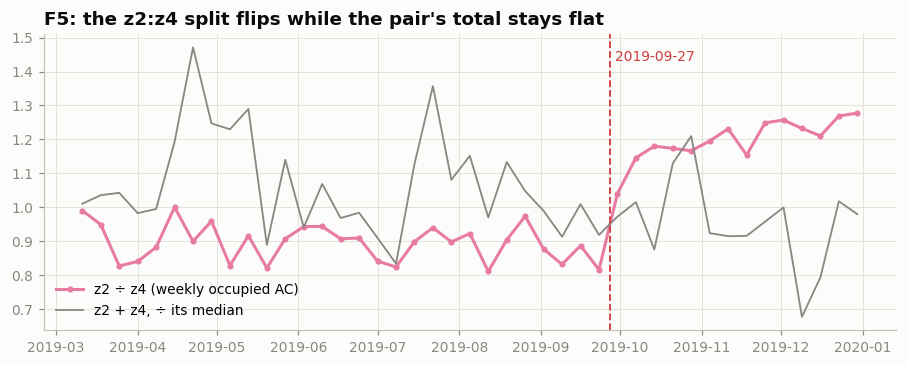

In [15]:
occ = h_all[h_all.is_workday & (h_all.ts >= "2019-03-07")]
occ = occ[[hr in R.ac_on_hours(int(f)) for f, hr in zip(occ.floor, occ.hour)]]
wk = occ.groupby(["floor", "zone", pd.Grouper(key="ts", freq="W-MON")]).ac_kwh.mean().unstack("zone")

f5 = wk.loc[5]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(f5.index, f5.z2 / f5.z4, color=viz.FLOOR_COLORS[5], marker="o", ms=3, label="z2 ÷ z4 (weekly occupied AC)")
ax.plot(f5.index, (f5.z2 + f5.z4) / (f5.z2 + f5.z4).median(), color=viz.MUTED, lw=1.2, label="z2 + z4, ÷ its median")
ax.axvline(pd.Timestamp("2019-09-27"), color=viz.STATUS["critical"], ls="--", lw=1.2)
ax.text(pd.Timestamp("2019-09-29"), ax.get_ylim()[1] * 0.97, "2019-09-27", color=viz.STATUS["critical"], va="top", fontsize=9)
ax.set_title("F5: the z2:z4 split flips while the pair's total stays flat"); ax.legend(loc="lower left")
bef = f5.loc["2019-08-12":"2019-09-23"]; aft = f5.loc["2019-09-30":"2019-11-11"]
print(f"z2:z4 ratio, 6 weeks before → after: {(bef.z2 / bef.z4).median():.2f} → {(aft.z2 / aft.z4).median():.2f}; "
      f"pair total after/before: {(aft.z2 + aft.z4).median() / (bef.z2 + bef.z4).median():.2f}")

**Checking every floor.** Looking for a sudden step in a single zone will not find this kind of event, because normal
seasonal changes are bigger (for example, a 25% drop at the mid-May semester break). The pattern to look for is **two
zones moving in opposite directions while their combined total stays flat**. For every pair of zones on every floor
over Mar–Dec 2019, the scan compares the median weekly AC energy in occupied hours over the 6 weeks before and after
each week. The score is the smaller of the two opposite changes minus the change in their total, so a high score
means a clear swap with little change in the combined load.

In [16]:
import itertools
warnings.filterwarnings("ignore", message="Mean of empty slice")   # F6 has no weeks after its file ends
rows = []
for f, w in wk.groupby(level=0):
    w = w.droplevel(0).dropna(axis=1, how="all")
    w = w.loc[:, w.mean() > 1]
    for a, b in itertools.combinations(w.columns, 2):
        for i in range(6, len(w) - 6):
            bef, aft = w.iloc[i - 6:i], w.iloc[i:i + 6]
            ra, rb = aft[a].median() / bef[a].median(), aft[b].median() / bef[b].median()
            rs = (aft[a] + aft[b]).median() / (bef[a] + bef[b]).median()
            if (ra - 1) * (rb - 1) < 0:
                rows.append({"floor": f, "pair": f"{a}/{b}", "week": w.index[i].date(), "zone a after/before": ra,
                             "zone b after/before": rb, "pair sum after/before": rs,
                             "score": min(abs(ra - 1), abs(rb - 1)) - abs(rs - 1)})
transfers = (pd.DataFrame(rows).sort_values("score", ascending=False)
             .drop_duplicates(["floor", "pair"]).groupby("floor").head(2))
transfers.round(2)

,floor,pair,week,zone a after/before,zone b after/before,pair sum after/before,score
182,6,z1/z5,2019-06-17,1.16,0.73,1.00,0.16
171,6,z1/z4,2019-06-10,1.16,0.83,0.98,0.14
108,5,z1/z4,2019-07-15,0.88,1.19,0.99,0.11
127,5,z2/z4,2019-10-07,1.12,0.87,0.99,0.11
46,4,z1/z2,2019-05-13,0.90,1.33,1.00,0.10
228,7,z4/z5,2019-10-14,1.13,0.88,1.04,0.08
27,3,z1/z5,2019-05-06,1.16,0.88,0.97,0.08
218,7,z2/z5,2019-10-14,1.09,0.88,1.03,0.06
79,4,z2/z4,2019-05-13,1.33,0.91,1.03,0.05
35,3,z2/z4,2019-07-15,0.92,1.06,0.99,0.04


**Results.** The known F5 zone 2/zone 4 transfer shows up, dated to the first full 6-week window after 2019-09-27,
which confirms that the scan works. The strongest pattern in the building is **F6 zones 1 and 5 around June 2019**.
Other pairs scoring above about 0.08 are possible cases. Each one should be checked against the minute-level data:
did the change happen within one afternoon, as it did on F5? If confirmed, it should be added to
`registry.CHANGE_POINTS` so that zone-level baselines are not trained across it. Floor-level baselines (`02`) are not
affected, because moving load between meters does not change the floor total.

**Next:** `00b_building_overview` shows where the energy goes and when. `00c_floor_profiles` covers what is unusual
about each floor.